# Dimensionality Reduction - PCA (Principal Component Analysis)

## 1. Apply PCA to reduce feature dimensionality while maintaining variance. 

### Load the data into a dataframe

In [14]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA

df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_disease.csv")

X = df.drop(columns=['target'])  
y = df['target']  

pca = PCA()
pca.fit(X)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


## 2. Determine the optimal number of principal components using the explained variance ratio. 

In [15]:
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

print("\nExplained variance by each component:")
for i, ratio in enumerate(explained_variance_ratio):
    print(f"  PC{i+1}: {ratio*100:.2f}%")

print("\nCumulative explained variance:")
for i, cum_ratio in enumerate(cumulative_variance):
    print(f"  Up to PC{i+1}: {cum_ratio*100:.2f}%")



Explained variance by each component:
  PC1: 28.47%
  PC2: 13.74%
  PC3: 10.55%
  PC4: 9.76%
  PC5: 9.20%
  PC6: 6.22%
  PC7: 4.23%
  PC8: 3.17%
  PC9: 3.06%
  PC10: 2.70%
  PC11: 2.41%
  PC12: 1.84%
  PC13: 1.69%
  PC14: 1.46%
  PC15: 0.60%
  PC16: 0.47%
  PC17: 0.27%
  PC18: 0.16%

Cumulative explained variance:
  Up to PC1: 28.47%
  Up to PC2: 42.21%
  Up to PC3: 52.76%
  Up to PC4: 62.52%
  Up to PC5: 71.72%
  Up to PC6: 77.94%
  Up to PC7: 82.17%
  Up to PC8: 85.35%
  Up to PC9: 88.41%
  Up to PC10: 91.10%
  Up to PC11: 93.52%
  Up to PC12: 95.36%
  Up to PC13: 97.05%
  Up to PC14: 98.51%
  Up to PC15: 99.11%
  Up to PC16: 99.57%
  Up to PC17: 99.84%
  Up to PC18: 100.00%


### **Decision** I will use the standard and balanced approach which is to take 95% of explained variance and reduce the feature from 18 to 12 which is 1 third reduction

In [16]:
pca = PCA(n_components=12)
X_pca = pca.fit_transform(X)

print(f"\nData shape after PCA {X_pca.shape}")


Data shape after PCA (303, 12)


## 3. Visualize PCA results using a scatter plot and cumulative variance plot.

### Scatter plot between the first two PC

In [17]:
import pandas as pd
import plotly.express as px

# pca doesn't return a dataframe

df_pca = pd.DataFrame(
    data=X_pca[:, :3],  
    columns=['PC1', 'PC2', 'PC3']
)

df_pca['Target'] = pd.Series(y).astype(str)


fig = px.scatter_3d(
    df_pca,
    x='PC1',
    y='PC2',
    z='PC3',
    color='Target',
    title='Interactive 3D PCA Plot',
    labels={'PC1': 'Principal Component 1', 'PC2': 'Principal Component 2', 'PC3': 'Principal Component 3'}
)

fig.update_traces(marker_size=3)
fig.show()

### Cumulative variance plot

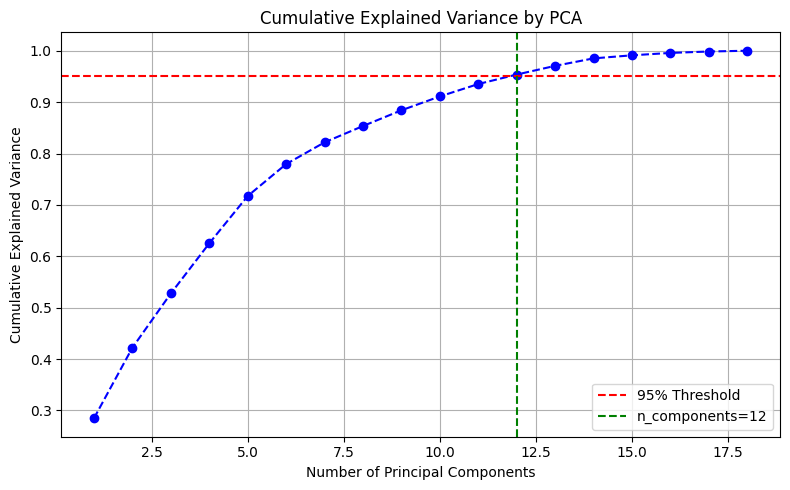

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by PCA')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Threshold')
plt.axvline(x=np.argmax(cumulative_variance >= 0.95) + 1, color='g', linestyle='--', label='n_components=12')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Save the PCA-transformed dataset 

In [19]:
import os

# Combine features and target

num_pcs = X_pca.shape[1]
pc_columns = [f'PC{i+1}' for i in range(num_pcs)]
X_pca_df = pd.DataFrame(X_pca, columns=pc_columns)


df_final = pd.concat([X_pca_df, y], axis=1)

folder_path = "../data"
file_name = "heart_diseasePCA.csv"
full_path = os.path.join(folder_path, file_name)

df_final.to_csv(full_path, index=False)

df_final

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,target
0,0.637861,0.487040,1.364671,-0.187044,-0.082339,1.061343,-0.143534,0.410498,0.285570,-1.107209,-0.063761,-0.526758,0
1,3.597942,0.689742,-0.406477,-0.065524,-0.578930,-1.250599,0.437605,0.408475,0.031683,-0.124088,0.069158,-0.491766,1
2,2.471558,-1.110346,-0.568826,0.195406,-0.397352,0.598856,-0.704686,0.148978,0.370995,0.169315,0.094485,0.003560,1
3,-1.445130,-0.405054,1.320414,2.548153,0.463377,1.343073,0.733455,-0.274201,-0.198212,-0.463521,-0.387236,-0.184531,0
4,-1.777110,-0.299346,0.770874,0.784282,-0.180538,0.183953,0.298354,0.974653,-0.293015,-0.415072,0.463109,0.416251,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,-0.591014,-1.280187,-0.339406,0.088368,1.259145,-0.069938,0.346861,-0.728720,0.165059,0.113821,0.635977,0.322946,1
299,2.598804,-0.573657,0.816519,0.531861,-1.410978,0.906163,-0.354653,-0.392908,-0.331082,0.274956,0.260557,0.027136,1
300,1.018696,-2.142081,0.761436,-1.041777,-1.006141,-0.638675,-0.422987,-0.364683,-0.197980,0.404739,0.010697,0.032716,1
301,-0.735806,0.811279,-0.617084,-0.187251,-0.795335,0.179347,-0.037538,0.895501,-0.060865,0.483633,0.919389,0.079523,1
